# 03 — Versão do MODIS, tamanho do pixel e comparação campo a campo
Análise feita com a skill **identificador-de-dados**, sempre olhando o que importa para **o nosso projeto**: juntar MODIS e VIIRS numa série mensal de focos.

- **Parte A** — A versão do MODIS muda ao longo dos anos. Isso quebra a série?
- **Parte B** — O pixel de cada sensor: o que é, quanto mede e como isso muda a contagem. *(centro da harmonização)*
- **Parte C** — Cada campo, MODIS ao lado do VIIRS: o que é igual e o que é diferente, e em que circunstâncias.

Dados: `data/raw/*.parquet` (2001–2025) e `data/raw/full/*_2020_full.parquet` (2020 com **todas** as colunas).

In [1]:
import io, requests, duckdb, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
RAW, REP = Path('../data/raw'), Path('../reports'); REP.mkdir(exist_ok=True)
con = duckdb.connect(); q = lambda s: con.execute(s).df()
M  = f"read_parquet('{RAW.as_posix()}/modis_*.parquet')"
V  = f"read_parquet('{RAW.as_posix()}/viirs-snpp_*.parquet')"
FM = f"read_parquet('{RAW.as_posix()}/full/modis_2020_full.parquet')"
FV = f"read_parquet('{RAW.as_posix()}/full/viirs-snpp_2020_full.parquet')"
COR = {'MODIS': '#E69F00', 'VIIRS': '#0072B2'}
plt.rcParams['figure.dpi'] = 110

---
# PARTE A — Versão do MODIS
## A1. Qual versão aparece em cada ano?
O Parquet local não guarda `version`. Lemos **12 trechos espalhados** de cada arquivo anual original (início, meio e fim do ano), sem baixar tudo.

In [2]:
from requests.adapters import HTTPAdapter, Retry
http = requests.Session(); http.mount('https://', HTTPAdapter(max_retries=Retry(total=6, backoff_factor=2)))
B = 'https://firms.modaps.eosdis.nasa.gov/data/country/modis'
amostras = []
for ano in range(2001, 2026):
    u = f'{B}/{ano}/modis_{ano}_Brazil.csv'
    tam = int(http.head(u).headers['Content-Length'])
    for off in np.linspace(0, tam - 40_000, 12).astype(int):
        linhas = http.get(u, timeout=60, headers={'Range': f'bytes={off}-{off+40_000}'}).text.split('\n')[1:-1]
        d = pd.read_csv(io.StringIO('\n'.join(linhas)), header=None, dtype=str, usecols=[5, 10])
        amostras.append(d[d[5].str.match(r'\d{4}-')].rename(columns={5: 'data', 10: 'version'}).assign(ano=ano))
ver = pd.concat(amostras).groupby(['ano', 'version']).agg(linhas=('data', 'size'), de=('data', 'min'), ate=('data', 'max')).reset_index()
ver

,ano,version,linhas,de,ate
0,2001,6.2,6041,2001-01-01,2001-12-31
1,2002,6.2,6069,2002-01-01,2002-12-31
2,2003,6.2,6084,2003-01-01,2003-12-31
3,2004,6.2,6084,2004-01-01,2004-12-31
4,2005,6.2,6078,2005-01-01,2005-12-31
5,2006,6.2,6069,2006-01-01,2006-12-31
6,2007,6.2,6070,2007-01-01,2007-12-31
7,2008,6.2,6090,2008-01-01,2008-12-31
8,2009,6.2,6111,2009-01-01,2009-12-31
9,2010,6.2,6081,2010-01-01,2010-12-31


## A2. O que a documentação diz
Fonte: *MODIS Collection 6 and 6.1 Active Fire Product User's Guide* (Giglio et al., v1.0, maio/2021).
- **Coleção 6 × 6.1:** o guia diz que os produtos de fogo ativo "may be freely intermixed" (podem ser misturados livremente). A 6.1 mudou só a calibração das bandas 1 e 2 (vermelho e infravermelho próximo); **as bandas térmicas usadas na detecção não mudaram**, e o FRP permanece o mesmo.
- **Versões do arquivo MCD14ML** (seção 5.5.2): a v2 acrescentou uma casa decimal em lat/lon e a coluna dia/noite; **a v3 "incorporates significantly improved typing of hot spots"** — ou seja, mudou a classificação do campo `type`.
- O nome oficial dos arquivos segue `MCD14ML.AAAAMM.<coleção>.<versão>` (ex.: `.006.02`).

**Hipótese de leitura dos códigos** (não está escrita no guia; deduzida do padrão do nome do arquivo):
| código FIRMS | anos | leitura provável |
|---|---|---|
| `6.2` | 2001–2017 | coleção 6, arquivo v2 |
| `6.03` | 2018–2022 | coleção 6, arquivo v3 |
| `61.03` | 2023–2025 | coleção 6.1, arquivo v3 |

## A3. Teste: as trocas de versão criam quebra nos dados?
Se a versão mudasse a detecção, veríamos saltos em 2017→2018 ou 2022→2023 em: confiança média, % de baixa confiança, FRP mediano, **% de cada `type`** e na razão VIIRS/MODIS.

In [3]:
t = q(f'''
WITH m AS (SELECT year(CAST(acq_date AS DATE)) ano, satellite, confidence::INT conf, frp, type FROM {M}),
     v AS (SELECT year(CAST(acq_date AS DATE)) ano, count(*) nv FROM {V} WHERE type=0 AND confidence IN ('n','h') GROUP BY 1)
SELECT ano, round(avg(conf),1) conf_media, round(100*avg((conf<30)::INT),1) pct_conf_baixa, round(median(frp),1) frp_mediana,
       round(100*avg((type=2)::INT),2) pct_type2_estatico, round(100*avg((type=3)::INT),3) pct_type3_offshore,
       round(any_value(nv) / sum((satellite='Aqua'  AND type=0 AND conf>=30)::INT), 2) viirs_por_aqua,
       round(any_value(nv) / sum((satellite='Terra' AND type=0 AND conf>=30)::INT), 2) viirs_por_terra
FROM m LEFT JOIN v USING (ano) GROUP BY 1 ORDER BY 1''')
t['versao'] = t.ano.map(lambda a: '6.2' if a <= 2017 else '6.03' if a <= 2022 else '61.03')
t

,ano,conf_media,pct_conf_baixa,frp_mediana,pct_type2_estatico,pct_type3_offshore,viirs_por_aqua,viirs_por_terra,versao
0,2001,65.9,5.7,18.1,0.83,0.003,NaN,NaN,6.2
1,2002,68.7,5.0,23.7,1.43,0.002,NaN,NaN,6.2
2,2003,68.8,4.7,23.4,2.83,0.003,NaN,NaN,6.2
3,2004,69.0,4.8,24.2,4.19,0.001,NaN,NaN,6.2
4,2005,69.1,4.9,24.0,1.08,0.002,NaN,NaN,6.2
5,2006,68.6,4.9,22.8,0.83,0.000,NaN,NaN,6.2
6,2007,69.3,4.9,24.6,0.66,0.001,NaN,NaN,6.2
7,2008,69.1,4.6,23.8,0.35,0.001,NaN,NaN,6.2
8,2009,67.2,5.1,20.9,0.21,0.000,NaN,NaN,6.2
9,2010,69.6,5.0,25.4,0.17,0.001,NaN,NaN,6.2


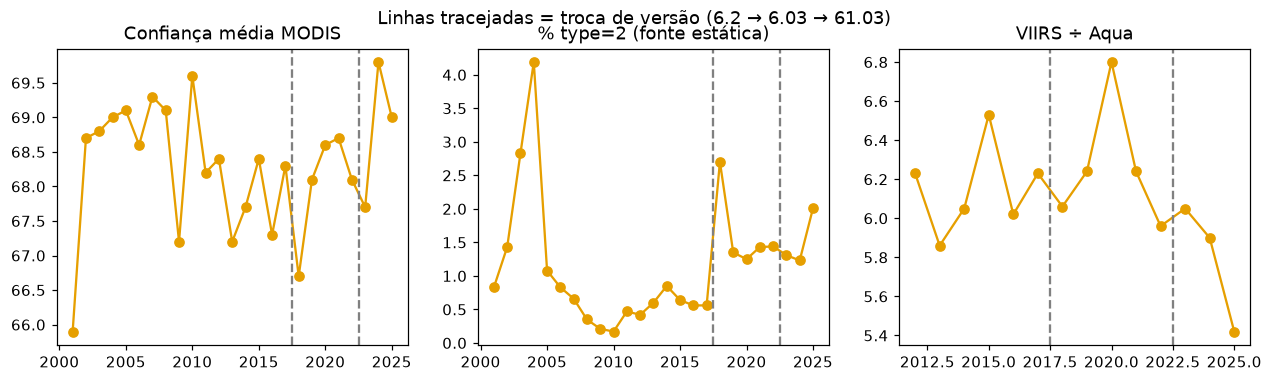

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for a, col, tit in [(ax[0], 'conf_media', 'Confiança média MODIS'), (ax[1], 'pct_type2_estatico', '% type=2 (fonte estática)'), (ax[2], 'viirs_por_aqua', 'VIIRS ÷ Aqua')]:
    a.plot(t.ano, t[col], 'o-', c=COR['MODIS']); a.set_title(tit)
    for x in [2017.5, 2022.5]: a.axvline(x, ls='--', c='gray')
fig.suptitle('Linhas tracejadas = troca de versão (6.2 → 6.03 → 61.03)'); fig.savefig(REP / 'a3_versao_modis.png', bbox_inches='tight')

## A4. Conclusão — versão do MODIS
| O que foi identificado | Classificação | Evidência | Até onde vale |
|---|---|---|---|
| Cada arquivo anual tem **uma única versão** (6.2 → 6.03 → 61.03) | Comprovado | A1: 12 trechos por ano, todos com a mesma versão | Arquivos anuais FIRMS do Brasil |
| Troca de coleção (6 → 6.1) **não muda a detecção** | Comprovado (documentação + dados) | Guia: "may be freely intermixed", bandas térmicas e FRP inalterados. Dados: sem salto em 2022→2023 na confiança (68,1 → 67,7), FRP (21,8 → 20,2) e VIIRS÷Aqua (5,96 → 6,05) | Detecção e FRP |
| Troca de versão do arquivo (v2 → v3) **muda o `type`** | Comprovado | Guia: v3 tem "significantly improved typing of hot spots". Dados: `type=2` vai de 0,56% (2017) para **2,70% (2018)** e fica em ~1,3–1,4% depois | Só o campo `type` |
| A queda da razão VIIRS÷MODIS em 2025 | **Não é efeito de versão** | A razão caiu em 2025 (5,42) sem troca de versão nesse ano; coincide com a deriva orbital (notebook 02) | Hipótese principal: deriva |

### O que isso muda no projeto
1. **A versão não quebra a contagem de focos.** Podemos juntar 2001–2025 do MODIS sem correção por versão.
2. **O filtro `type = 0` não é uniforme no tempo:** antes de 2018 o MODIS classificava menos pixels como fonte estática. Usar `type` registro a registro cria um degrau artificial pequeno (~0,8% dos focos) em 2018.
3. **Solução proposta:** em vez de filtrar por `type` em cada linha, criar **uma máscara única de fontes estáticas** (células 0,25° que tiveram `type=2` em qualquer ano, em qualquer sensor) e aplicá-la igualmente a todos os anos e aos dois sensores. Assim o filtro fica idêntico no tempo e entre sensores.

---
# PARTE B — O pixel de cada sensor
## B1. O que é um pixel aqui
O sensor varre a Terra em linhas. Cada leitura cobre um retângulo do chão (**pixel**). O algoritmo marca o pixel como "foco" se ele estiver mais quente que os vizinhos. O FIRMS publica **o centro desse retângulo** e o tamanho dele:
- `scan` = largura do pixel **ao longo da varredura** (de lado a lado da faixa), em km;
- `track` = comprimento do pixel **ao longo da trajetória** do satélite, em km.

O pixel **cresce quanto mais longe do centro da faixa** (o sensor olha de lado, em ângulo). O guia do MODIS dá a fórmula (Ichoku & Kaufman, 2005), reproduzida abaixo.

,ângulo,scan_km,track_km,área_km2
0,0.0,1.00,1.00,1.00
1,11.0,1.04,1.02,1.07
2,22.0,1.20,1.09,1.30
3,33.0,1.53,1.22,1.87
4,44.0,2.31,1.47,3.40
5,55.0,4.83,2.01,9.69


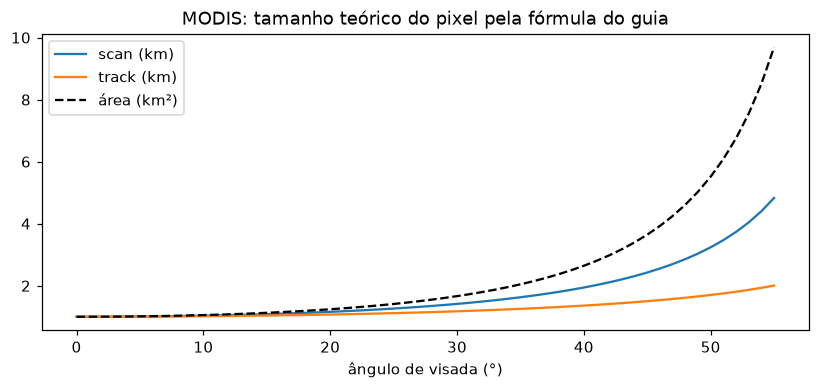

In [5]:
Re, h = 6378.137, 705.0; r = Re + h
def modis_pixel(theta_graus, res=1.0):
    th = np.radians(theta_graus); s = res / h
    raiz = np.sqrt((Re / r)**2 - np.sin(th)**2)
    dS = Re * s * (np.cos(th) / raiz - 1)          # ao longo da varredura (scan)
    dT = r * s * (np.cos(th) - raiz)               # ao longo da trajetória (track)
    return dS, dT
ang = np.linspace(0, 55, 56); dS, dT = modis_pixel(ang)
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(ang, dS, label='scan (km)'); ax.plot(ang, dT, label='track (km)'); ax.plot(ang, dS*dT, 'k--', label='área (km²)')
ax.set_xlabel('ângulo de visada (°)'); ax.set_title('MODIS: tamanho teórico do pixel pela fórmula do guia'); ax.legend()
fig.savefig(REP / 'b1_pixel_modis_teorico.png', bbox_inches='tight')
pd.DataFrame({'ângulo': ang[::11], 'scan_km': dS[::11].round(2), 'track_km': dT[::11].round(2), 'área_km2': (dS*dT)[::11].round(2)})

## B2. Tamanho observado do pixel nos dados (2020 inteiro)

sensor            MODIS        VIIRS
scan  count  405388.000  1666244.000
      mean        1.635        0.461
      std         0.829        0.089
      min         1.000        0.320
      5%          1.000        0.350
      50%         1.300        0.440
      95%         3.600        0.630
      max         4.800        0.800
track count  405388.000  1666244.000
      mean        1.219        0.483
      std         0.252        0.116
      min         1.000        0.360
      5%          1.000        0.360
      50%         1.100        0.450
      95%         1.800        0.710
      max         2.000        0.780
area  count  405388.000  1666244.000
      mean        2.198        0.228
      std         1.742        0.094
      min         1.000        0.137
      5%          1.000        0.140
      50%         1.430        0.199
      95%         6.480        0.440
      max         9.600        0.624

Razão de área (mediana MODIS ÷ mediana VIIRS): 7.2


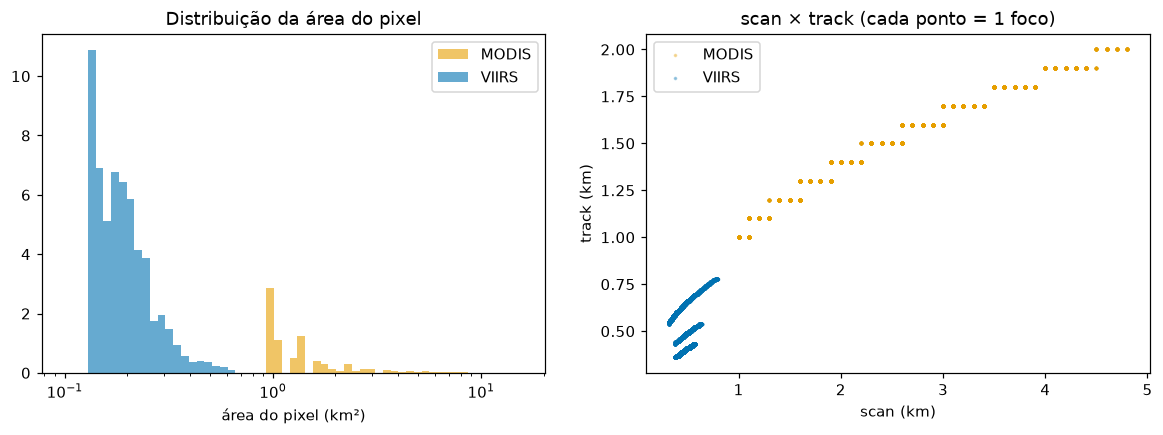

In [6]:
px = q(f'''SELECT 'MODIS' sensor, scan, track, scan*track area FROM {FM}
          UNION ALL SELECT 'VIIRS', scan, track, scan*track FROM {FV}''')
resumo = px.groupby('sensor')[['scan', 'track', 'area']].describe(percentiles=[.05, .5, .95]).T.round(3)
display(resumo)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for s in ['MODIS', 'VIIRS']:
    d = px[px.sensor == s]
    ax[0].hist(d.area, bins=np.logspace(-1, 1.2, 60), alpha=.6, color=COR[s], label=s, density=True)
    ax[1].scatter(d.scan.sample(20000, random_state=0), d.track.sample(20000, random_state=0), s=2, alpha=.3, color=COR[s], label=s)
ax[0].set_xscale('log'); ax[0].set_xlabel('área do pixel (km²)'); ax[0].legend(); ax[0].set_title('Distribuição da área do pixel')
ax[1].set_xlabel('scan (km)'); ax[1].set_ylabel('track (km)'); ax[1].legend(); ax[1].set_title('scan × track (cada ponto = 1 foco)')
fig.savefig(REP / 'b2_pixel_observado.png', bbox_inches='tight')
print('Razão de área (mediana MODIS ÷ mediana VIIRS):', round(px[px.sensor=='MODIS'].area.median() / px[px.sensor=='VIIRS'].area.median(), 1))

## B3. Quantos pixels VIIRS cabem dentro de um pixel MODIS **de verdade**?
**Critério:** para cada foco do **Aqua (dia)**, contamos os focos VIIRS **do mesmo dia (passagem da tarde)** cujo centro cai **dentro do retângulo** do pixel MODIS (`|Δlon| ≤ scan/2`, `|Δlat| ≤ track/2`).
**Simplificações declaradas:** o retângulo é alinhado leste-oeste/norte-sul (a órbita real é inclinada ~8° — erro pequeno); a busca é feita dentro de faixas de 0,5° de latitude (pixels na borda da faixa perdem vizinhos, < 5% dos casos).

In [7]:
casa = f'''
CREATE OR REPLACE TABLE aq AS SELECT row_number() OVER () id, latitude lat, longitude lon, acq_date, scan, track, frp, scan*track area,
       floor(latitude*2) faixa FROM {FM} WHERE satellite='Aqua' AND daynight='D' AND type=0 AND confidence::INT>=30;
CREATE OR REPLACE TABLE vi AS SELECT row_number() OVER () id, latitude lat, longitude lon, acq_date, frp, floor(latitude*2) faixa
       FROM {FV} WHERE daynight='D' AND type=0 AND confidence IN ('n','h');
CREATE OR REPLACE TABLE par AS
SELECT a.id aid, v.id vid, a.area, a.frp frp_m, v.frp frp_v FROM aq a JOIN vi v
  ON a.acq_date=v.acq_date AND a.faixa=v.faixa
 AND abs(v.lat-a.lat)*111.0 <= a.track/2 AND abs(v.lon-a.lon)*111.0*cos(radians(a.lat)) <= a.scan/2;'''
con.execute(casa)
dentro = q('''SELECT a.id, a.area, a.frp frp_m, count(p.vid) n_viirs, coalesce(sum(p.frp_v),0) frp_v_soma
              FROM aq a LEFT JOIN par p ON a.id=p.aid GROUP BY ALL''')
dentro['faixa_area'] = pd.cut(dentro.area, [0, 1.2, 1.6, 2.5, 4, 10], labels=['≤1,2', '1,2–1,6', '1,6–2,5', '2,5–4', '>4'])
tab = dentro.groupby('faixa_area', observed=True).agg(pixels_modis=('id', 'size'), viirs_por_pixel_mediana=('n_viirs', 'median'),
        viirs_por_pixel_media=('n_viirs', 'mean'), pct_sem_nenhum_viirs=('n_viirs', lambda s: round(100*(s==0).mean(), 1))).round(2)
tab

,pixels_modis,viirs_por_pixel_mediana,viirs_por_pixel_media,pct_sem_nenhum_viirs
faixa_area,,,,
"≤1,2",66364,0.0,0.86,58.2
"1,2–1,6",38761,0.0,1.10,52.8
"1,6–2,5",41467,1.0,1.44,49.3
"2,5–4",22616,1.0,1.93,45.1
>4,25777,1.0,2.87,40.5


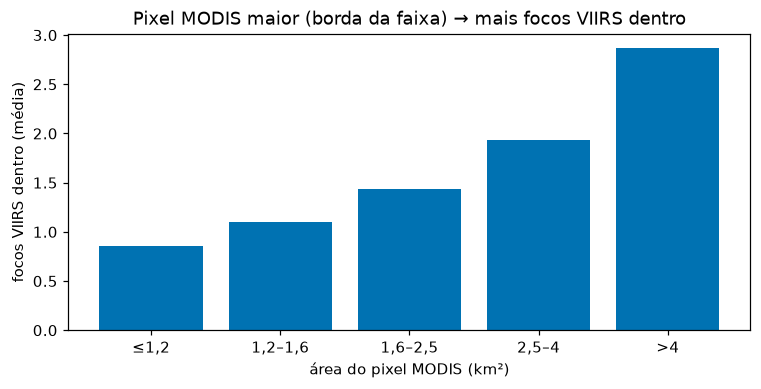

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(tab.index.astype(str), tab.viirs_por_pixel_media, color=COR['VIIRS'])
ax.set_xlabel('área do pixel MODIS (km²)'); ax.set_ylabel('focos VIIRS dentro (média)')
ax.set_title('Pixel MODIS maior (borda da faixa) → mais focos VIIRS dentro'); fig.savefig(REP / 'b3_viirs_por_pixel_modis.png', bbox_inches='tight')

## B4. Quais fogos o MODIS deixa de ver? (curva de detecção)
**Critério:** pegamos os focos VIIRS da tarde em **células 0,5° × dia onde o Aqua detectou algo** (garante que o MODIS estava observando aquela área — evita confundir *não observado* com *não detectado*). Para cada um, perguntamos: ele está dentro de algum pixel MODIS detectado?
**Viés declarado:** exigir que o Aqua tenha detectado algo na célula favorece áreas com fogo; a curva é uma **estimativa** da sensibilidade, não um valor exato.

,focos_viirs,pct_visto_pelo_modis
faixa_frp,,
<2,4669,13.1
2–5,89044,22.7
5–10,175122,34.8
10–20,146363,46.7
20–50,101407,56.6
50–100,28738,62.2
>100,12389,64.7


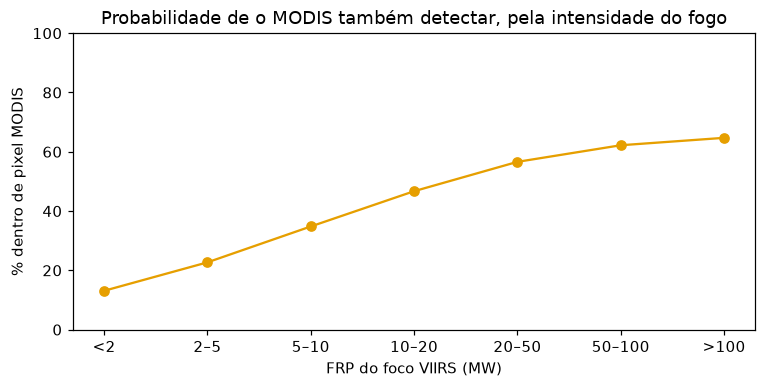

In [9]:
det = q(f'''
WITH obs AS (SELECT DISTINCT acq_date, faixa, floor(lon*2) col FROM aq),
     vv AS (SELECT v.*, floor(v.lon*2) col FROM vi v JOIN obs o ON v.acq_date=o.acq_date AND v.faixa=o.faixa AND floor(v.lon*2)=o.col)
SELECT vv.id, vv.frp, (vv.id IN (SELECT vid FROM par)) visto_pelo_modis FROM vv''')
det['faixa_frp'] = pd.cut(det.frp, [0, 2, 5, 10, 20, 50, 100, 1e5], labels=['<2', '2–5', '5–10', '10–20', '20–50', '50–100', '>100'])
curva = det.groupby('faixa_frp', observed=True).agg(focos_viirs=('id', 'size'), pct_visto_pelo_modis=('visto_pelo_modis', lambda s: round(100*s.mean(), 1)))
display(curva)
fig, ax = plt.subplots(figsize=(8, 3.5)); ax.plot(curva.index.astype(str), curva.pct_visto_pelo_modis, 'o-', c=COR['MODIS'])
ax.set_xlabel('FRP do foco VIIRS (MW)'); ax.set_ylabel('% dentro de pixel MODIS'); ax.set_ylim(0, 100)
ax.set_title('Probabilidade de o MODIS também detectar, pela intensidade do fogo'); fig.savefig(REP / 'b4_curva_deteccao.png', bbox_inches='tight')

## B5. O FRP fica equivalente quando somamos os VIIRS dentro do pixel MODIS?
Se o FRP é energia, somar os pixels VIIRS que cabem num pixel MODIS deveria dar algo próximo do FRP do MODIS.

Pixels MODIS com ≥1 VIIRS dentro: 94,817 de 194,985 (49%)
Soma FRP VIIRS ÷ FRP MODIS — mediana 0.73 | p25 0.36 | p75 1.38
Correlação (log): 0.60


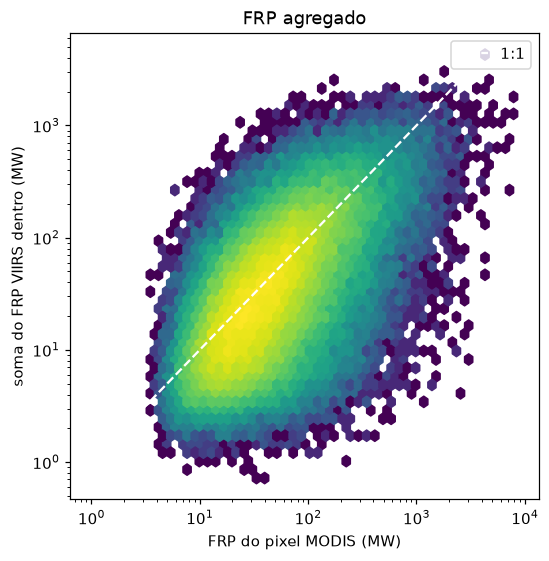

In [10]:
ok = dentro[(dentro.n_viirs > 0) & (dentro.frp_m > 0) & (dentro.frp_v_soma > 0)]   # FRP ≤ 0 é inválido (ver C7)
razao = (ok.frp_v_soma / ok.frp_m)
print(f'Pixels MODIS com ≥1 VIIRS dentro: {len(ok):,} de {len(dentro):,} ({len(ok)/len(dentro):.0%})')
print(f'Soma FRP VIIRS ÷ FRP MODIS — mediana {razao.median():.2f} | p25 {razao.quantile(.25):.2f} | p75 {razao.quantile(.75):.2f}')
print(f'Correlação (log): {np.corrcoef(np.log(ok.frp_m), np.log(ok.frp_v_soma))[0,1]:.2f}')
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.hexbin(ok.frp_m, ok.frp_v_soma, xscale='log', yscale='log', gridsize=45, bins='log', cmap='viridis', mincnt=1)
x = np.logspace(0, 3.5); ax.plot(x, x, 'w--', label='1:1'); ax.legend()
ax.set_xlabel('FRP do pixel MODIS (MW)'); ax.set_ylabel('soma do FRP VIIRS dentro (MW)'); ax.set_title('FRP agregado')
fig.savefig(REP / 'b5_frp_agregado.png', bbox_inches='tight')

## B6. Conclusão — o pixel
| O que foi identificado | Classificação | Evidência |
|---|---|---|
| O pixel MODIS **varia de 1 a 9,6 km²** conforme o ângulo de visada | Comprovado | Fórmula do guia: 1,0 km² no nadir → 9,7 km² a 55°; observado: mín 1,0, mediana 1,43, máx 9,6 km² (B1, B2) |
| O pixel VIIRS **varia pouco: 0,14 a 0,62 km²** | Comprovado | B2: mediana 0,199 km². O VIIRS tem um esquema de agregação a bordo que segura o crescimento do pixel na borda |
| Em área, **1 pixel MODIS típico ≈ 7,2 pixels VIIRS** | Comprovado | razão das medianas (B2) |
| Pixel MODIS maior → mais focos VIIRS dentro | Comprovado | B3: média de 0,86 VIIRS por pixel MODIS ≤1,2 km² e 2,87 em pixels >4 km² |
| O retângulo nominal **não é a área real vista** pelo MODIS | Comprovado | B3: 58% dos pixels MODIS pequenos não têm nenhum centro VIIRS dentro do retângulo, mas no notebook 02, com raio de 1 km, 93% tinham VIIRS perto. O sensor "enxerga" além do retângulo (resposta espacial borrada) e a posição tem erro |
| O MODIS **perde mais os fogos fracos** | Comprovado (estimativa) | B4: VIIRS com FRP 2–5 MW → só 23% caem em pixel MODIS detectado; FRP >100 MW → 65%. Valores são limite inferior por causa do retângulo estrito |
| FRP somado é **só parcialmente equivalente** | Equivalente sob critério, com ruído | B5: soma VIIRS ÷ MODIS mediana 0,73 (p25 0,36, p75 1,38), correlação log 0,60 |

### Por que o pixel explica a diferença nas contagens
O sensor detecta fogo quando ele aquece o pixel acima dos vizinhos. O mesmo fogo **ocupa uma fração muito maior de um pixel de 0,2 km² do que de um pixel de 1,4 km²**, então aquece mais o pixel pequeno e é detectado mais facilmente. Por isso:
1. **Fogos pequenos/fracos** aparecem no VIIRS e não no MODIS (B4).
2. **Fogos grandes** aparecem nos dois, mas o VIIRS os quebra em vários pixels (B3).
3. A razão VIIRS÷MODIS **depende do tamanho típico dos fogos da região** (muitos fogos agrícolas pequenos → razão alta) e da **geometria da passagem** (pixel MODIS na borda da faixa).

### O que isso muda no projeto
- O fator `k` **não pode ser um número único**: ele depende da região (tamanho típico dos fogos) e do mês. Isso confirma o mapa de `k` por bloco do notebook 00 (2,9 a 5,3).
- Uma melhoria possível: usar `scan × track` (área do pixel MODIS) como variável do modelo de conversão.
- **Não dá para converter ponto a ponto**; a harmonização tem que ser **por célula e mês** (contagens agregadas).

---
# PARTE C — Campo a campo (2020 completo, todas as colunas)
Para cada campo: o que é, como aparece nos dados de cada sensor e, no fim, **igual em que circunstância × diferente em que circunstância**.

In [11]:
dm, dv = q(f'SELECT * FROM {FM}'), q(f'SELECT * FROM {FV}')
def lado_a_lado(cm, cv=None, por=None):
    cv = cv or cm; linhas = {}
    for nome, d, c in [('MODIS', dm, cm), ('VIIRS', dv, cv)]:
        s = d[c]; info = {'coluna': c, 'tipo': str(s.dtype), 'nulos': int(s.isna().sum()), 'distintos': s.nunique()}
        if pd.api.types.is_numeric_dtype(s):
            info.update({'mín': s.min(), 'p5': s.quantile(.05), 'mediana': s.median(), 'p95': s.quantile(.95), 'máx': s.max(),
                         'zeros': int((s == 0).sum()), 'negativos': int((s < 0).sum())})
        else:
            vc = s.value_counts(normalize=True).head(6).round(3); info['valores (fração)'] = ', '.join(f'{k}: {v}' for k, v in vc.items())
        linhas[nome] = info
    out = pd.DataFrame(linhas)
    if por: display(pd.concat({n: d.groupby(por)[c].describe().round(2) for n, d, c in [('MODIS', dm, cm), ('VIIRS', dv, cv)]}))
    return out
print(f'Registros 2020 — MODIS: {len(dm):,} | VIIRS: {len(dv):,}')

Registros 2020 — MODIS: 405,388 | VIIRS: 1,666,244


### C1. `latitude` / `longitude` — posição do centro do pixel

In [12]:
lado_a_lado('latitude')

,MODIS,VIIRS
coluna,latitude,latitude
tipo,float64,float64
nulos,0,0
distintos,184694,1121099
mín,-33.5577,-33.71109
p5,-21.957365,-21.724364
mediana,-10.65105,-10.085275
p95,-2.94704,-2.853602
máx,5.1491,5.16622
zeros,0,0


In [13]:
lado_a_lado('longitude')

,MODIS,VIIRS
coluna,longitude,longitude
tipo,float64,float64
nulos,0,0
distintos,197995,1165180
mín,-73.6692,-73.66846
p5,-64.2829,-64.563804
mediana,-52.9975,-52.765
p95,-42.057975,-41.715394
máx,-34.8234,-34.8022
zeros,0,0


Precisão gravada (casas decimais) e o que ela significa em metros:

In [14]:
for n, d in [('MODIS', dm), ('VIIRS', dv)]:
    casas = d.latitude.astype(str).str.split('.').str[1].str.len().max()
    print(f'{n}: até {casas} casas → precisão ≈ {111_000 / 10**casas:.1f} m (pixel ~{d.scan.median()*1000:.0f} m)')

MODIS: até 4 casas → precisão ≈ 11.1 m (pixel ~1300 m)


VIIRS: até 5.0 casas → precisão ≈ 1.1 m (pixel ~440 m)


**Leitura:** a coordenada é gravada com precisão de ~11 m (MODIS) e ~1 m (VIIRS), muito mais fina que o próprio pixel (~1.300 m e ~440 m). **Precisão gravada ≠ exatidão:** o ponto marca o centro de um pixel grande, não a posição do fogo.

| | Igual quando… | Diferente quando… |
|---|---|---|
| **latitude / longitude** | Mesma unidade (graus decimais), mesma referência (centro do pixel), mesma cobertura (Brasil: lat −33,7 a 5,2; lon −73,7 a −34,8) | O ponto representa áreas de tamanhos diferentes (1–9,6 km² × 0,14–0,62 km²) e tem casas decimais diferentes (4 × 5) |
| **Classificação** | **Equivalente sob critério**: só comparável depois de agregar em células maiores que o pixel MODIS (0,25° ≈ 28 km) | |

### C2. `acq_date` — data da passagem (UTC)

In [15]:
lado_a_lado('acq_date')

,MODIS,VIIRS
coluna,acq_date,acq_date
tipo,str,str
nulos,0,0
distintos,366,366
valores (fração),"2020-09-13: 0.026, 2020-09-14: 0.021, 2020-09-...","2020-09-13: 0.022, 2020-09-12: 0.02, 2020-09-0..."


| | Igual quando… | Diferente quando… |
|---|---|---|
| **acq_date** | Sempre: texto AAAA-MM-DD, em UTC, 366 dias distintos em 2020 nos dois, pico no mesmo dia (13/09) | Nunca no formato. Lembrar: é data UTC, não local |
| **Classificação** | **Idêntico** | |

### C3. `acq_time` — hora da passagem (HHMM, UTC)

In [16]:
hm = lambda d: d.acq_time.astype(int)//100 + d.acq_time.astype(int)%100/60
display(pd.DataFrame({n: (hm(d)).describe().round(2) for n, d in [('MODIS Terra', dm[dm.satellite=='Terra']), ('MODIS Aqua', dm[dm.satellite=='Aqua']), ('VIIRS', dv)]}))
lado_a_lado('acq_time')

,MODIS Terra,MODIS Aqua,VIIRS
count,170155.00,235233.00,1666244.00
mean,9.49,15.68,13.19
std,5.76,4.04,5.73
min,0.23,3.25,2.75
25%,2.35,16.57,5.32
50%,13.47,17.05,16.63
75%,14.07,17.52,17.27
max,15.95,19.23,19.27


,MODIS,VIIRS
coluna,acq_time,acq_time
tipo,str,str
nulos,0,0
distintos,722,467
valores (fração),"1652: 0.009, 1641: 0.009, 1742: 0.008, 1733: 0...","1703: 0.014, 1644: 0.012, 1656: 0.011, 1709: 0..."


**Leitura:** em UTC, o Terra aparece em dois blocos (~13–14 h UTC de manhã local e ~2 h UTC à noite); Aqua e VIIRS ficam juntos (~17 h UTC à tarde local e ~5 h UTC à noite).

| | Igual quando… | Diferente quando… |
|---|---|---|
| **acq_time** | Formato HHMM em UTC, resolução de 1 minuto. **Aqua × VIIRS**: mesmos horários (4 min de diferença) | **Terra × VIIRS**: horários diferentes (manhã/noite cedo × tarde/madrugada). O fogo tem ciclo diário (mais forte à tarde), então o Terra vê menos focos |
| **Classificação** | **Idêntico** no formato; os valores só são comparáveis no par Aqua × VIIRS | |

### C4. `satellite` / `instrument` — quem observou

In [17]:
display(lado_a_lado('satellite')); lado_a_lado('instrument')

,MODIS,VIIRS
coluna,satellite,satellite
tipo,str,str
nulos,0,0
distintos,2,1
valores (fração),"Aqua: 0.58, Terra: 0.42",N: 1.0


,MODIS,VIIRS
coluna,instrument,instrument
tipo,str,str
nulos,0,0
distintos,1,1
valores (fração),MODIS: 1.0,VIIRS: 1.0


| | Igual quando… | Diferente quando… |
|---|---|---|
| **satellite** | — | Sempre: MODIS tem 2 satélites (Aqua 58%, Terra 42%); VIIRS tem 1 (`N` = Suomi-NPP) |
| **instrument** | Sempre: um rótulo fixo por arquivo | — |
| **Classificação** | `satellite` **distinto**; `instrument` **idêntico** (só rotula) | |

**No projeto:** como Terra e Aqua passam em horários diferentes, a conversão deve ser calculada **separada para Terra e para Aqua** (no notebook 03-A: VIIRS ≈ 6,1× Aqua e ≈ 9,8× Terra).

### C5. `daynight` — passagem diurna ou noturna

In [18]:
lado_a_lado('daynight')

,MODIS,VIIRS
coluna,daynight,daynight
tipo,str,str
nulos,0,0
distintos,2,2
valores (fração),"D: 0.771, N: 0.229","D: 0.684, N: 0.316"


| | Igual quando… | Diferente quando… |
|---|---|---|
| **daynight** | Mesmos valores (D/N) e mesma regra nos dados standard (ângulo solar de 85°, notebook 00) | A proporção muda: MODIS 77% dia, VIIRS 68% dia. O VIIRS detecta relativamente mais fogo à noite (pixel menor capta fogo noturno, mais fraco) |
| **Classificação** | **Idêntico** como campo; a **proporção** dia/noite é consequência do sensor | |

**No projeto:** calcular a conversão separada para dia e noite.

### C6. `confidence` — confiança da detecção

In [19]:
display(dm.assign(c=dm.confidence.astype(int)).groupby('daynight').c.describe().round(1))
display(pd.crosstab(dv.confidence, dv.daynight, normalize='columns').round(3))
lado_a_lado('confidence')

,count,mean,std,min,25%,50%,75%,max
daynight,,,,,,,,
D,312384.0,67.8,21.9,0.0,54.0,70.0,85.0,100.0
N,93004.0,71.0,24.3,0.0,55.0,73.0,94.0,100.0


daynight,D,N
confidence,,
h,0.104,0.011
l,0.128,0.000
n,0.768,0.989


,MODIS,VIIRS
coluna,confidence,confidence
tipo,str,str
nulos,0,0
distintos,101,3
valores (fração),"100: 0.1, 75: 0.018, 73: 0.017, 70: 0.017, 74:...","n: 0.838, l: 0.088, h: 0.075"


| | Igual quando… | Diferente quando… |
|---|---|---|
| **confidence** | O objetivo é o mesmo (separar detecção fraca de forte) | Sempre na forma: MODIS número 0–100 (101 valores; 10% dos registros com 100); VIIRS 3 letras. No VIIRS a regra depende de dia/noite: `l` **só existe de dia** (12,8%), à noite 98,9% é `n` |
| **Classificação** | **Não comparável diretamente** | |

**No projeto:** o filtro (MODIS ≥ 30, VIIRS n|h) é uma **escolha nossa**, não uma equivalência comprovada. Para testar: ver se a razão VIIRS÷MODIS fica mais estável com outro limiar (ex.: ≥ 50).

### C7. `frp` — potência radiativa do fogo (MW)

In [20]:
lado_a_lado('frp', por='daynight')

count   mean     std   min    25%    50%    75%      max
      daynight                                                              
MODIS D          312384.0  60.26  134.06  0.00  14.60  27.10  57.10  8589.80
      N           93004.0  28.27   58.33  0.00   8.30  14.30  28.10  3048.50
VIIRS D         1140423.0  17.36   28.91 -3.55   5.21   8.73  17.24  1395.16
      N          525821.0   3.26    6.63  0.00   1.19   1.86   3.14   556.78

,MODIS,VIIRS
coluna,frp,frp
tipo,float64,float64
nulos,0,0
distintos,7890,18296
mín,0.0,-3.55
p5,6.5,0.97
mediana,23.4,5.97
p95,179.7,46.7
máx,8589.8,1395.16
zeros,37,375


| | Igual quando… | Diferente quando… |
|---|---|---|
| **frp** | Mesma grandeza e unidade (MW) | Por ponto: mediana 23,4 (MODIS) × 5,97 (VIIRS). À noite: 14,3 × 1,86. O FRP é a potência **do pixel**, e o pixel VIIRS é ~7× menor |
| **Valores inválidos** | MODIS: 37 zeros, nenhum negativo | VIIRS: 375 zeros e **17 negativos** em 2020 (sem significado físico) |
| **Classificação** | **Equivalente sob critério** só somado por área (B5: mediana 0,73, correlação 0,60); **não comparável** ponto a ponto | |

### C8. `brightness` (MODIS) × `bright_ti4` (VIIRS) — temperatura de brilho no infravermelho médio (K)

In [21]:
lado_a_lado('brightness', 'bright_ti4', por='daynight')

count    mean    std    min     25%     50%     75%    max
      daynight                                                                
MODIS D          312384.0  332.37  19.71  300.0  319.70  327.50  338.70  506.4
      N           93004.0  314.11  14.22  300.0  305.50  309.80  317.70  504.4
VIIRS D         1140423.0  344.13  12.17  208.0  335.87  342.32  350.49  367.0
      N          525821.0  315.03  13.57  295.0  305.52  310.75  320.76  367.0

,MODIS,VIIRS
coluna,brightness,bright_ti4
tipo,float64,float64
nulos,0,0
distintos,1819,6887
mín,300.0,208.0
p5,304.9,303.71
mediana,324.3,337.32
p95,365.6,367.0
máx,506.4,367.0
zeros,0,0


Saturação: o VIIRS I4 satura perto de 367 K (pixels muito quentes ficam travados num teto). Quantos pixels estão no topo?

In [22]:
print('VIIRS bright_ti4 ≥ 367 K:', int((dv.bright_ti4 >= 367).sum()), f'({100*(dv.bright_ti4 >= 367).mean():.2f}%)')
print('MODIS brightness ≥ 400 K:', int((dm.brightness >= 400).sum()), f'({100*(dm.brightness >= 400).mean():.2f}%)')
print('Confiança dos VIIRS ≥ 367 K:', dv[dv.bright_ti4 >= 367].confidence.value_counts().to_dict())

VIIRS bright_ti4 ≥ 367 K: 135949 (8.16%)
MODIS brightness ≥ 400 K: 4578 (1.13%)
Confiança dos VIIRS ≥ 367 K: {'h': 124547, 'l': 11402}


**Leitura:** 8,16% dos pixels VIIRS estão travados em **367 K** (saturação da banda I4), e quase todos são `h` (124.547 de 135.949). O MODIS chega a 506 K. Também há VIIRS abaixo de 300 K (mín. 208 K), enquanto o MODIS começa exatamente em 300 K.

| | Igual quando… | Diferente quando… |
|---|---|---|
| **brightness × bright_ti4** | Medem temperatura de brilho no infravermelho médio, em kelvin | Banda diferente (MODIS 21/22 ≈ 4 µm × VIIRS I4 3,74 µm), pixel diferente, **teto diferente** (VIIRS satura em 367 K) |
| **Classificação** | **Não comparável diretamente** | |

**No projeto:** não usar na harmonização.

### C9. `bright_t31` (MODIS) × `bright_ti5` (VIIRS) — temperatura de brilho no infravermelho térmico (K)

In [23]:
lado_a_lado('bright_t31', 'bright_ti5', por='daynight')

count    mean   std     min     25%     50%     75%  \
      daynight                                                            
MODIS D          312384.0  303.11  7.96  268.50  298.10  302.90  308.10   
      N           93004.0  292.75  4.54  266.70  290.90  293.20  295.20   
VIIRS D         1140423.0  303.27  9.73  251.16  297.53  302.83  308.26   
      N          525821.0  290.90  5.97  224.29  289.17  291.88  293.99   

                   max  
      daynight          
MODIS D         400.10  
      N         400.10  
VIIRS D         384.63  
      N         369.92

,MODIS,VIIRS
coluna,bright_t31,bright_ti5
tipo,float64,float64
nulos,0,0
distintos,780,11628
mín,266.7,224.29
p5,288.6,285.26
mediana,300.2,298.38
p95,314.7,315.68
máx,400.1,384.63
zeros,0,0


| | Igual quando… | Diferente quando… |
|---|---|---|
| **bright_t31 × bright_ti5** | Infravermelho térmico (~11 µm), em kelvin. As distribuições são **parecidas** (mediana 300,2 × 298,4; dia 302,9 × 302,8; noite 293,2 × 291,9), porque essa banda mede principalmente a superfície de fundo, não o fogo | Banda não é a mesma (MODIS 31 × VIIRS I5 11,45 µm) e o pixel é diferente; extremos diferem (máx 400 × 385 K) |
| **Classificação** | **Não comparável diretamente**, mesmo com distribuições parecidas | |

### C10. `scan` / `track` — tamanho do pixel (km)

In [24]:
display(lado_a_lado('scan')); lado_a_lado('track')

,MODIS,VIIRS
coluna,scan,scan
tipo,float64,float64
nulos,0,0
distintos,39,49
mín,1.0,0.32
p5,1.0,0.35
mediana,1.3,0.44
p95,3.6,0.63
máx,4.8,0.8
zeros,0,0


,MODIS,VIIRS
coluna,track,track
tipo,float64,float64
nulos,0,0
distintos,11,43
mín,1.0,0.36
p5,1.0,0.36
mediana,1.1,0.45
p95,1.8,0.71
máx,2.0,0.78
zeros,0,0


| | Igual quando… | Diferente quando… |
|---|---|---|
| **scan / track** | Mesmo significado (tamanho do pixel em km, ao longo da varredura e da trajetória) | Valores: MODIS scan 1–4,8 / track 1–2,0; VIIRS scan 0,32–0,80 / track 0,36–0,78. O MODIS cresce muito na borda; o VIIRS quase não cresce |
| **Classificação** | **Equivalente sob critério** (mesma unidade, km); os valores são **distintos** por natureza do sensor | |

**No projeto:** é o campo que explica a diferença de contagem (Parte B). Vale guardar `scan × track` nos Parquets da harmonização.

### C11. `version`

In [25]:
lado_a_lado('version')

,MODIS,VIIRS
coluna,version,version
tipo,str,str
nulos,0,0
distintos,1,1
valores (fração),6.03: 1.0,2: 1.0


| | Igual quando… | Diferente quando… |
|---|---|---|
| **version** | Dentro de cada arquivo anual há uma só versão | Entre sensores sempre (MODIS 6.03 em 2020 × VIIRS 2); no MODIS muda entre anos (Parte A) |
| **Classificação** | **Distinto** (metadado do produto) | |

### C12. `type` — tipo do foco

In [26]:
lado_a_lado('type')

,MODIS,VIIRS
coluna,type,type
tipo,int64,int64
nulos,0,0
distintos,3,3
mín,0,0
p5,0.0,0.0
mediana,0.0,0.0
p95,0.0,0.0
máx,3,3
zeros,400332,1649138


| | Igual quando… | Diferente quando… |
|---|---|---|
| **type** | Mesmos códigos (0 vegetação, 2 fonte estática, 3 offshore) e mesma intenção | Proporções diferentes em 2020: `type=2` 1,25% × 0,82%; `type=3` 4 × 3.429 registros. No MODIS, a regra mudou em 2018 (Parte A) |
| **Classificação** | **Equivalente sob critério** (uso como filtro), mas **não uniforme no tempo** no MODIS | |

**No projeto:** substituir o filtro por linha por uma **máscara única de fontes estáticas** (Parte A).

## Tabela final — igual × diferente, por circunstância

| Campo | Classificação | Igual quando… | Diferente quando… | Uso no projeto |
|---|---|---|---|---|
| latitude / longitude | Equivalente sob critério | unidade, referência, cobertura | área do pixel (7×) e casas decimais | agregar em célula 0,25° |
| acq_date | **Idêntico** | sempre (UTC) | — | agregar por mês |
| acq_time | **Idêntico** (formato) | Aqua × VIIRS (4 min) | Terra × VIIRS | separar Terra e Aqua |
| satellite | Distinto | — | sempre | separar Terra e Aqua |
| instrument | **Idêntico** | sempre | — | rótulo do sensor |
| daynight | **Idêntico** (regra) | valores e regra | proporção dia/noite | separar dia e noite |
| confidence | Não comparável | objetivo | escala e regra | filtro escolhido, testar limiar |
| frp | Equivalente só agregado | unidade (MW) | valor por ponto | não usar na contagem |
| brightness × bright_ti4 | Não comparável | grandeza (K) | banda, pixel, saturação 367 K | não usar |
| bright_t31 × bright_ti5 | Não comparável | grandeza e distribuição parecida | banda e pixel | não usar |
| scan / track | Equivalente sob critério | unidade (km) | tamanho (1–9,6 × 0,14–0,62 km²) | explica `k`; possível variável do modelo |
| version | Distinto | — | sempre | não afeta contagem; afeta `type` |
| type | Equivalente (filtro) | códigos | proporção e regra (MODIS 2018) | máscara única de fontes estáticas |

### O que levar para a Fase 2 (harmonização)
1. Harmonizar **por célula e mês**, nunca ponto a ponto.
2. Calcular a conversão **separada por satélite (Terra / Aqua), por dia/noite e por região**.
3. Calibrar com **2012–2021** (antes da deriva orbital).
4. Trocar o filtro `type = 0` por uma **máscara única de fontes estáticas**.
5. Considerar a **área do pixel MODIS** como explicação da variação do `k`.